In [3]:
from dotenv import load_dotenv
load_dotenv()

True

In [1]:
from langchain_core.tools import tool
from pydantic import Field, BaseModel
import json


# Define input schema with Pydantic
class calculatorinput(BaseModel):
    """Input schema for calculator tool."""
    expression: str = Field(
        description="The Mathematical expression to evaluate, e.g,'25 * 4'"
        )

@tool(args_schema=calculatorinput)
def calculator(expression: str) -> str:
    """Useful for performing mathematical calculations. Use this when you need to compute numbers."""

    try:
        allowed_builtinfunc = {
            "sum" : sum,
            "min" : min,
            "max" : max,
            "pow" : pow,
            "abs" : abs,
            "round" : round
        } 


        result = eval(expression, {"__builtins__": {}}, allowed_builtinfunc )
        return f"Result is {result}"

    except Exception as error:
        return f"Error evaluating expression {error}"


def main():
    print("Simple Calculator Tool Demo\n")
    print("=" * 80 + "\n")    

    print("Tool Name: ", calculator.name)
    print("Tool Description: ", calculator.description)
    print("\n Schema: ", json.dumps(calculator.args_schema.model_json_schema(), indent=2))


    print("\n" + "=" * 80 + "\n")

    # Test the tool directly
    test_expressions = [
        "25 * 17",
        "(100 + 50) / 2",
        "pow(12, 2)",  # 12 squared
    ]


    for exp in test_expressions:
        print(f"\nExpression :{exp}")
        result = calculator.invoke({"expression": exp})
        print(f"Result: {result}")

    
    
    print("\n" + "=" * 80 + "\n")
    print(" Tool created successfully!")
    print("\n Key Takeaways:")
    print("   • Tools are created with @tool decorator")
    print("   • Pydantic models define parameter schemas")
    print("   • Descriptions help LLMs understand when to use tools")


if __name__ == "__main__":
    main()


Simple Calculator Tool Demo


Tool Name:  calculator
Tool Description:  Useful for performing mathematical calculations. Use this when you need to compute numbers.

 Schema:  {
  "description": "Input schema for calculator tool.",
  "properties": {
    "expression": {
      "description": "The Mathematical expression to evaluate, e.g,'25 * 4'",
      "title": "Expression",
      "type": "string"
    }
  },
  "required": [
    "expression"
  ],
  "title": "calculatorinput",
  "type": "object"
}



Expression :25 * 17
Result: Result is 425

Expression :(100 + 50) / 2
Result: Result is 75.0

Expression :pow(12, 2)
Result: Result is 144


 Tool created successfully!

 Key Takeaways:
   • Tools are created with @tool decorator
   • Pydantic models define parameter schemas
   • Descriptions help LLMs understand when to use tools


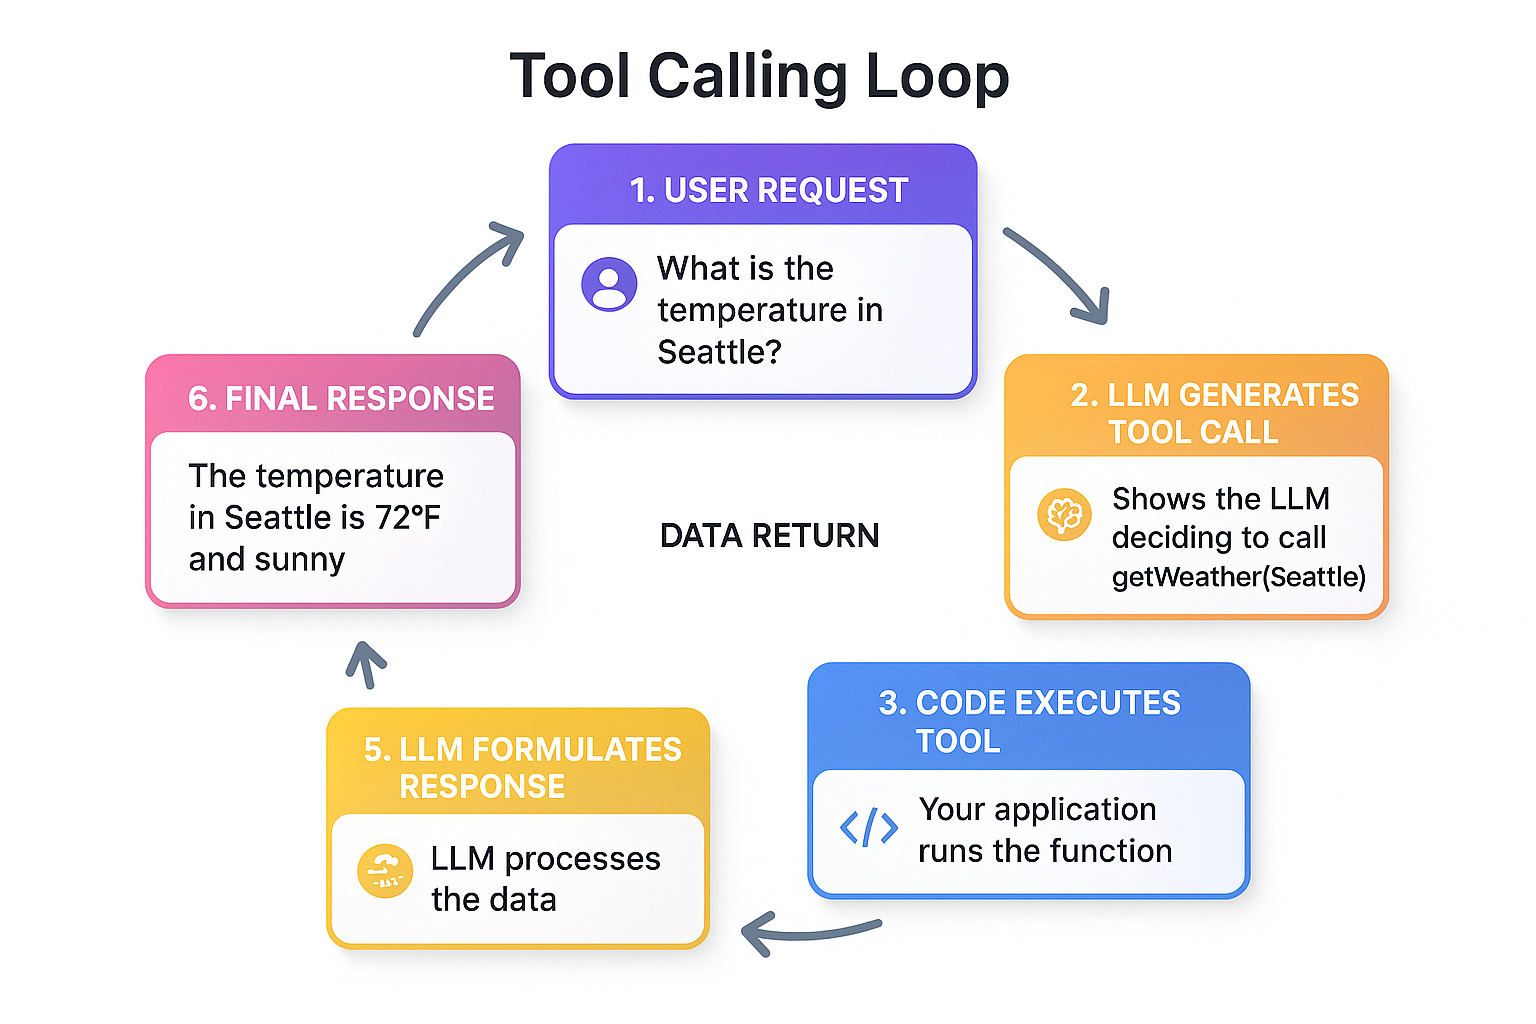

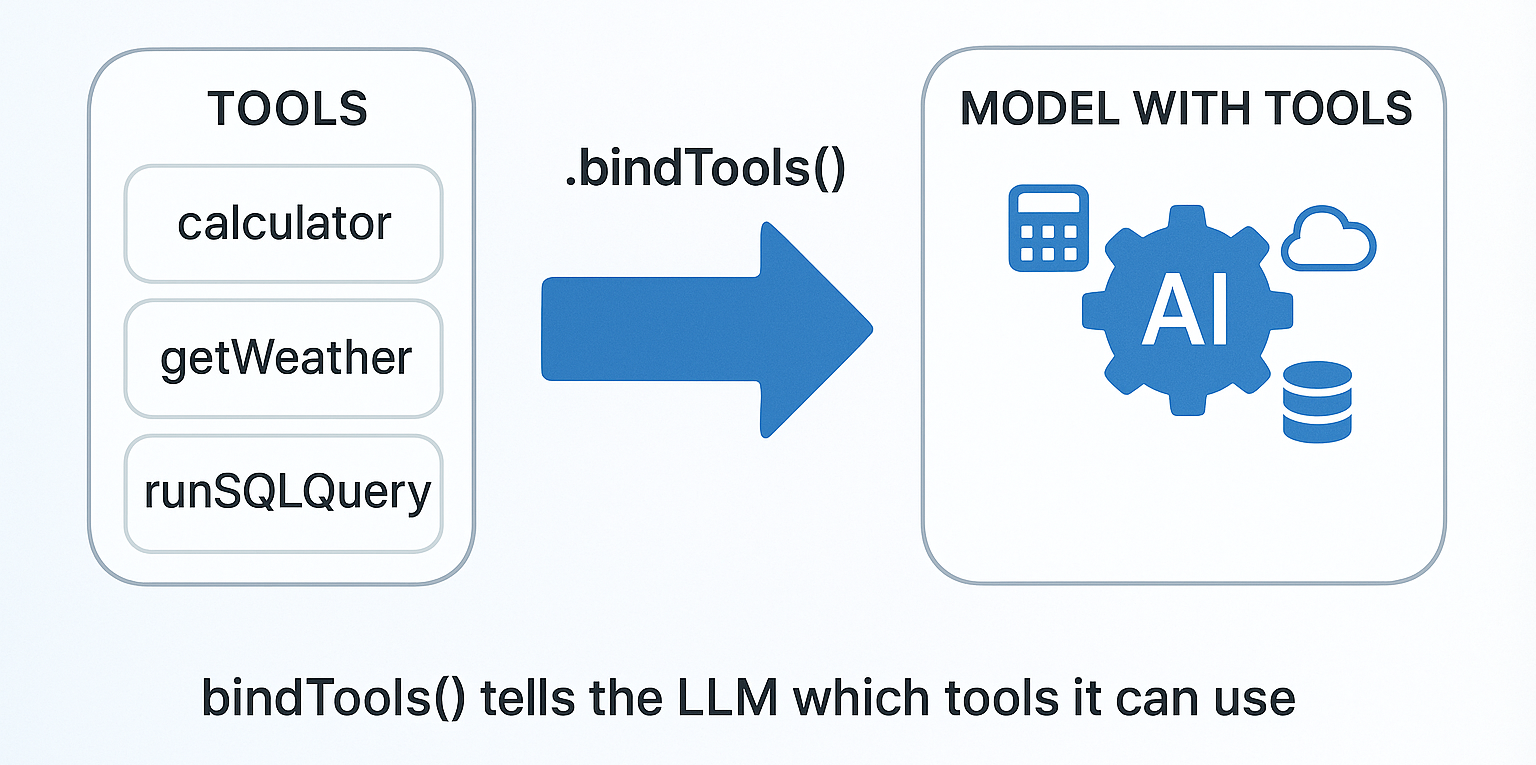

### Binding and Invoking tools

In [9]:
from langchain_groq import ChatGroq
from langchain_core.tools import tool
from pydantic import BaseModel, Field



class calculatorinput_1(BaseModel):
    """Input schema for caclculator tool"""
    expression: str = Field(
        description="The mathematical expression to evaluate, e.g., '25 * 4"
        )
@tool(args_schema=calculatorinput_1)
def calculator_1(expression1: str) -> str:
    """Perform mathematical calculation"""

    result = eval(expression1, {"__bulltins__": {}},{})
    return str(result)


def main():
    model = ChatGroq(
        model="openai/gpt-oss-120b",
        temperature=0

    )    

    model_with_tools = model.bind_tools([calculator_1])

    response = model_with_tools.invoke("what is 25 * 5?")

    print("Response: ", response)
    print("\nTool Calls: ",response.tool_calls[0])


if __name__ == "__main__":
    main()    



Response:  content='' additional_kwargs={'reasoning_content': 'User asks "what is 25 * 5?" Simple multiplication. Use calculator function.', 'tool_calls': [{'id': 'fc_5ea44b27-8b1d-4312-8a1c-e4423e8e6a37', 'function': {'arguments': '{"expression":"25 * 5"}', 'name': 'calculator_1'}, 'type': 'function'}]} response_metadata={'token_usage': {'completion_tokens': 51, 'prompt_tokens': 141, 'total_tokens': 192, 'completion_time': 0.107656873, 'completion_tokens_details': {'reasoning_tokens': 19}, 'prompt_time': 0.006917345, 'prompt_tokens_details': None, 'queue_time': 0.309560047, 'total_time': 0.114574218}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_fe269835c7', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'} id='lc_run--01a1ab96-810c-7ef3-abd4-70b8ed586414-0' tool_calls=[{'name': 'calculator_1', 'args': {'expression': '25 * 5'}, 'id': 'fc_5ea44b27-8b1d-4312-8a1c-e4423e8e6a37', 'type': 'tool_call'}] invalid_tool_cal

### Example 3: Complete Tool Call Loop
In this example, you'll see the complete flow: LLM generates tool call, your code executes the tool, and results return to LLM for the final response.



In [12]:
from langchain_groq import ChatGroq
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from pydantic import BaseModel, Field


class weatherinput(BaseModel):
    city: str = Field(description="city name")


@tool(args_schema=weatherinput)
def get_weather(city: str) -> str:
    """Get current weather  for a city"""

    temps = {
        "Seatle": 24,
        "Paris": 18,
        "Tokyo": 40
    }

    temp = temps.get(city, 72)
    return f"Current temperature is in {city}: {temp}°F"


def main():

    print("Tool name:", get_weather.name)
    print("Tool description:", get_weather.description)
    # print("\n Schema: ", json.dumps(get_weather.args_schema.model_json_schema(), indent=2))

    model = ChatGroq(
        model="openai/gpt-oss-120b",
        temperature=0

    )


    # binding tool with model
    model_with_tools = model.bind_tools([get_weather]) 

    # Step 1: Get tool call from LLM
    query = "What is the weather in seatle?"
    response1 = model_with_tools.invoke(query)
    print("tool call: ", response1.tool_calls[0]) 

    # Step 2: Execute the tool    
    tool_call = response1.tool_calls[0]
    tool_result = get_weather.invoke(tool_call["args"]) 

    
    # Step 3: Send result back to LLM
    messages = [
        HumanMessage(content=query),
        AIMessage(content="", tool_calls=response1.tool_calls),
        ToolMessage(content=tool_result, tool_call_id=tool_call["id"])
    ]


    final_response = model.invoke(messages)
    print("Step 3 - Final answer:", final_response.content)



if __name__ == "__main__":
    main()    

Tool name: get_weather
Tool description: Get current weather  for a city
tool call:  {'name': 'get_weather', 'args': {'city': 'Seattle'}, 'id': 'fc_b367a23a-02b5-4541-87a2-abfa88e8ec4a', 'type': 'tool_call'}
Step 3 - Final answer: The current temperature in Seattle is **72 °F**.


### Example 4: Multi-Tool System

In [16]:
from pydantic import BaseModel, Field
from langchain_core.tools import tool
from langchain_groq import ChatGroq




class weatherinput1(BaseModel):
    city: str = Field(description="City name")


class searchinput(BaseModel):
    query: str = Field(description="search query")


class calcu2input(BaseModel):
    expression: str = Field(description="The mathematical expression to evaluate, e.g., '23 * 4'")


@tool(args_schema=calcu2input)
def calculator2(expression: str) -> str:
    """Perform mathematical calculations."""
    return str(eval(expression, {"__builtins__": {}}, {}))



@tool(args_schema=searchinput)
def search(query: str) -> str:
    """Search for factual information."""
    results = {
        "Capital of France" : "Paris",
        "Population of Tokyo" : "14 million"
    }
    return results.get(query.lower(), "Not results found")



@tool(args_schema=weatherinput1)
def get_weather2(city: str) -> str:
    """Get current weather for a city."""
    temps = {
        "Paris" : 35,
        "Tokyo" : 25,
        "Islambad" : 45
    }
    temp = temps.get(city, 44)
    return f"weather in {temp}"


def main():
    model = ChatGroq(
        model="openai/gpt-oss-120b",
        temperature=0

    )

    model_with_tools1 = model.bind_tools([calculator2,search,get_weather2])  


    queries = [
        "What is 125 * 8?",
        "What's the capital of France?",
        "What's the weather in Tokyo?",        
    ]  

    for query in queries:
        response3 = model_with_tools1.invoke(query)
        if response3.tool_calls:
            print(f"query: {query}")
            print(f"tool: {response3.tool_calls[0]['name']}")
            print()


if __name__ == "__main__":
    main()

query: What's the weather in Tokyo?
tool: get_weather2

